<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/mae5911/p_value_2-fisher.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0.58748417,0.3480006,0.58748417,0.6438000
0.77540406,0.5184941,0.77540406,0.8118466
0.05414555,0.3076604,0.05414555,0.5943147
0.93066884,0.7134350,0.93066884,0.9347884
0.58169369,0.2989391,0.58169369,0.5830628
0.16535319,0.3315845,0.16535319,0.6241592


[1] 5665

[1] 0

[1] 125

0.4686867,-0.06700880
-0.3054460,-0.41296948
0.4275690,0.07060333
0.3651864,-1.62287790
-0.5681686,-0.99988674
-0.3338396,0.07009805
-0.3271559,-1.01114878
-1.0482068,-0.34309398
-2.2396707,0.31713769
1.6444617,1.05523035
-1.4191244,0.59323657


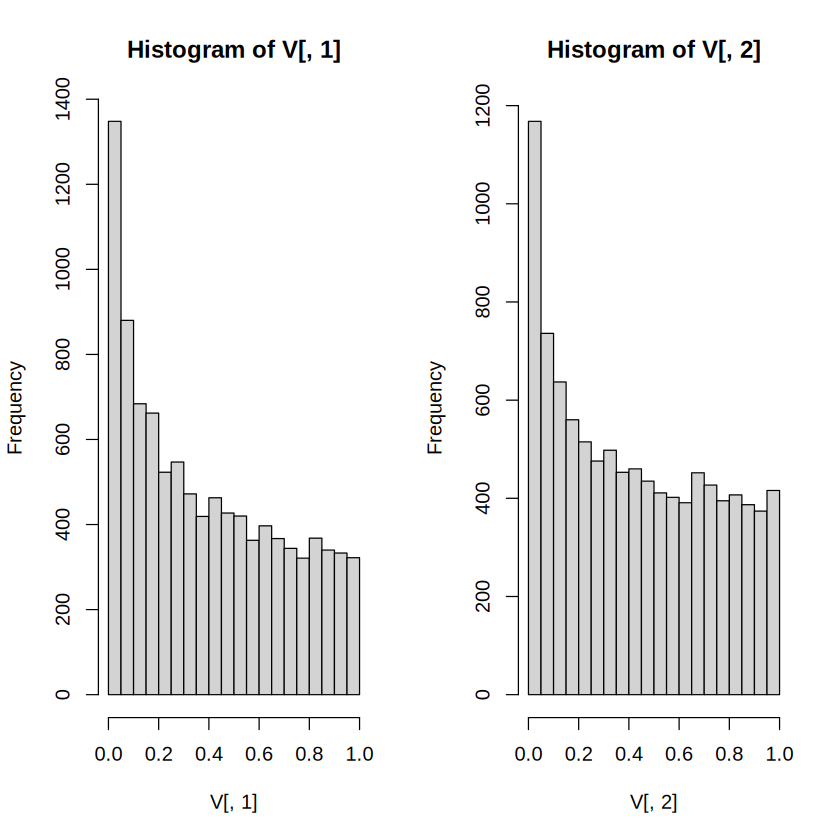

In [10]:
#Z ~ N_2(mu, I), mu = (mu1, mu2)
# H0: mu1 = mu2 =0
# H0' mu1 = mu2

n = 100
mu1 = 0.1
mu2 = 0
A = list()
k = 0
MC=10000
V = matrix(0, MC, 4)

mu = cbind(rep(mu1,n),rep(mu2,n))
for (i in 1:MC) {
  z = mu + matrix(rnorm(2*n),n,2)

  # H0: mu1 = mu2 = 0
  T1 = n * sum(colMeans(z)^2)

  # H0': mu1 = mu2
  T2 = n * diff(colMeans(z))^2/2
  valor.p1 = 1-pchisq(T1, 2) # 2 graus de liberdade
  valor.p2 = 1-pchisq(T2, 1) # 1 grau de liberdade
  valor.s1 = 1-pchisq(T1, 2)
  valor.s2 = 1-pchisq(T2, 2)

  V[i,] = c(valor.p1, valor.p2, valor.s1, valor.s2)

  # espero que valor.p1 < valor.p2

  if(valor.p1 > valor.p2 & valor.p1 > 0.1 & valor.p2 < 0.05) {
      k=k+1
      A[[k]] = list()
      A[[k]]$sample = z
      A[[k]]$valorp1 = valor.p1
      A[[k]]$valorp2 = valor.p2
      A[[k]]$valors1 = valor.s1
      A[[k]]$valors2 = valor.s2
  }
}

# hist(V[,1])
head(V)
par(mfrow=c(1,2))
hist(V[,1])
hist(V[,2])

sum(V[,1]>V[,2])
sum(V[,3]>V[,4])
length(A)
A[[1]]

